# Projeto Mestre — clima, ENSO e previsão de alertas de dengue

## O que este projeto procura descobrir

O objetivo principal é verificar se informações climáticas locais e indicadores de El Niño e La Niña ajudam a antecipar alertas de dengue em Ribeirão Preto com **4, 8, 12 e 16 semanas** de antecedência.

O notebook separa três perguntas:

1. clima e dengue aparecem relacionados nos dados históricos?
2. acrescentar clima melhora previsões feitas somente com casos anteriores e época do ano?
3. quais informações a LSTM utilizou para produzir cada previsão?

As análises medem associação e contribuição preditiva. Elas não demonstram que uma variável climática, isoladamente, causou um surto.

## Decisões principais tomadas antes da análise final

- definição principal: alerta pelo canal endêmico causal em incidência por 100 mil habitantes;
- análise de sensibilidade: P75 causal preservado no Projeto 1;
- clima local disponível com atraso mínimo de uma semana;
- ONI e demais índices globais disponíveis com atraso conservador de quatro semanas;
- treino por data-alvo até 2021, validação em 2022–2023 e avaliação retrospectiva em 2024–2025;
- PR AUC como medida principal de discriminação, sempre apresentada junto à prevalência;
- comparação obrigatória entre sazonalidade, epidemiologia, clima, modelo sem ENSO e modelo completo;
- resultados negativos são preservados;
- Captum explica o comportamento da LSTM, não causalidade epidemiológica.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / 'src/dengue_research').exists() else cwd.parent
OUTPUT_DIR = PROJECT_ROOT / 'outputs/projeto_mestre'
REEXECUTE = False  # True treina todos os modelos novamente; pode demorar.

if REEXECUTE or not (OUTPUT_DIR / 'resultados_completos.json').exists():
    subprocess.run(
        [sys.executable, str(PROJECT_ROOT / 'scripts/run_master_study.py')],
        cwd=PROJECT_ROOT,
        check=True,
    )

results = json.loads((OUTPUT_DIR / 'resultados_completos.json').read_text(encoding='utf-8'))
associations = pd.read_csv(OUTPUT_DIR / 'associacoes_climaticas.csv')
enso = pd.read_csv(OUTPUT_DIR / 'resumo_enso.csv')
ablation = pd.read_csv(OUTPUT_DIR / 'comparacao_com_sem_clima.csv')
stability = pd.read_csv(OUTPUT_DIR / 'estabilidade_lstm_sementes.csv')
episodes = pd.read_csv(OUTPUT_DIR / 'episodios_alerta.csv')
print('Projeto:', PROJECT_ROOT)
print('Resultados:', OUTPUT_DIR)

Projeto: /media/lorenzo/SSD/Projetos/ML-Dengue
Resultados: /media/lorenzo/SSD/Projetos/ML-Dengue/outputs/projeto_mestre


## 1. Qualidade e origem dos dados

Esta seção verifica datas, ausências, duplicações e valores impossíveis. O denominador `dem` é usado provisoriamente como população residente, mas sua fonte e a alteração observada em 2023 ainda precisam de confirmação documental. Isso é uma pendência científica explícita, não uma informação escondida.

In [2]:
display(pd.Series(results['data_audit'], name='valor').to_frame())
display(pd.Series(results['population_audit'], name='valor').to_frame())

,valor
n_rows,784
n_columns,73
start,2010-12-26
end,2025-12-28
frequency,W-SUN
duplicated_dates,0
missing_values,0
infinite_numeric_values,0
case_min,6.0
case_median,126.5


,valor
column,dem
interpretation_status,hipótese operacional de população residente; c...
missing,0
non_positive,0
minimum,702739.0
maximum,711825.0
n_unique,2
changes,"[{'date': '2010-12-26', 'value': 711825.0}, {'..."


## 2. O que é considerado alerta

O canal endêmico compara a incidência semanal com o histórico da mesma época em anos anteriores. Somente semanas anteriores são utilizadas. Um alerta exige quatro semanas consecutivas acima do limite superior.

O termo correto é **alerta epidemiológico construído pelo canal**. Ele não equivale sozinho a uma declaração oficial de epidemia.

In [3]:
display(episodes)

,episode_id,start,end,duration_weeks,peak_incidence_per_100k,mean_incidence_per_100k
0,1,2015-11-29,2016-02-21,13,844.730095,425.666421
1,2,2019-05-26,2019-07-14,8,149.755909,67.555228
2,3,2022-08-14,2022-11-06,13,33.997120,24.973727
3,4,2023-10-15,2023-12-17,10,50.943522,36.841559
4,5,2024-01-21,2024-01-28,2,243.618185,221.205882
5,6,2024-09-01,2024-12-22,17,110.994267,69.350490


## 3. Como El Niño e La Niña são representados

A coluna ONI é utilizada como informação contínua nos modelos. Para gráficos descritivos, valores a partir de `+0,5` são chamados de El Niño, valores até `-0,5` de La Niña e os demais de neutros. Essa classificação é operacional e precisa ser confrontada com a fonte oficial antes da redação final.

Nos modelos, ONI aparece com pelo menos quatro semanas de atraso. Assim, uma previsão não utiliza um índice que ainda não estaria disponível na data de emissão.

In [4]:
display(enso.round(3))

,horizon_weeks,enso_phase,n_weeks,mean_future_incidence,median_future_incidence,future_alert_prevalence
0,4,el_nino,194,129.670,50.659,0.170
1,4,la_nina,190,41.519,14.962,0.068
2,4,neutro,247,33.868,9.412,0.069
3,8,el_nino,194,129.939,54.648,0.170
4,8,la_nina,186,44.021,15.523,0.070
5,8,neutro,251,31.929,8.570,0.068
6,12,el_nino,194,125.273,54.081,0.170
7,12,la_nina,185,43.340,15.594,0.070
8,12,neutro,252,36.069,8.429,0.067
9,16,el_nino,194,120.294,53.173,0.186


## 4. Relações climáticas observadas

As correlações abaixo usam blocos de oito semanas para representar a dependência entre semanas próximas. Elas ajudam a descrever a relação temporal, mas não provam causa e efeito.

In [5]:
display(
    associations.sort_values('spearman', key=lambda s: s.abs(), ascending=False)
    .head(30)
    .round(3)
)

,horizon_weeks,feature,outcome,spearman,lower_95,upper_95,interpretation
68,12,media_temperatura_semana_lag_1,incidencia_futura,0.389,0.257,0.501,associação descritiva; não causal
4,4,media_temperatura_semana_lag_8,incidencia_futura,0.387,0.252,0.503,associação descritiva; não causal
36,8,media_temperatura_semana_lag_4,incidencia_futura,0.387,0.246,0.496,associação descritiva; não causal
6,4,media_temperatura_semana_lag_12,incidencia_futura,0.367,0.225,0.480,associação descritiva; não causal
38,8,media_temperatura_semana_lag_8,incidencia_futura,0.367,0.230,0.489,associação descritiva; não causal
70,12,media_temperatura_semana_lag_4,incidencia_futura,0.367,0.229,0.500,associação descritiva; não causal
34,8,media_temperatura_semana_lag_1,incidencia_futura,0.361,0.206,0.491,associação descritiva; não causal
102,16,media_temperatura_semana_lag_1,incidencia_futura,0.358,0.205,0.480,associação descritiva; não causal
116,16,media_umidade_semana_lag_12,incidencia_futura,-0.355,-0.458,-0.210,associação descritiva; não causal
2,4,media_temperatura_semana_lag_4,incidencia_futura,0.346,0.203,0.461,associação descritiva; não causal


## 5. A comparação central da tese

São comparados cinco conjuntos de informação:

- `seasonal_only`: somente época do ano e tendência;
- `epidemiology_only`: sazonalidade e histórico da dengue;
- `climate_only`: sazonalidade e variáveis climáticas;
- `full_without_enso`: casos e clima, mas sem ONI;
- `full`: casos, clima local, ONI e outros índices.

O clima será considerado preditivamente útil apenas se melhorar resultados fora do treino de forma consistente. Um resultado inferior também deve ser mantido e discutido.

In [6]:
columns = ['horizon_weeks','feature_set','model','prevalence','pr_auc','brier','precision','recall_sensitivity','false_alarms_per_year']
display(ablation[columns].sort_values(['horizon_weeks','model','pr_auc'], ascending=[True,True,False]).round(3))

,horizon_weeks,feature_set,model,prevalence,pr_auc,brier,precision,recall_sensitivity,false_alarms_per_year
2,4,epidemiology_only,logistic_regression,0.183,0.339,0.133,0.000,0.000,1.003
6,4,full_without_enso,logistic_regression,0.183,0.303,0.224,0.378,0.737,11.539
8,4,full,logistic_regression,0.183,0.260,0.237,0.317,0.684,14.048
0,4,seasonal_only,logistic_regression,0.183,0.173,0.193,0.164,0.526,25.587
4,4,climate_only,logistic_regression,0.183,0.145,0.200,0.127,0.421,27.594
3,4,epidemiology_only,random_forest,0.183,0.444,0.125,0.273,0.158,4.014
7,4,full_without_enso,random_forest,0.183,0.373,0.133,0.409,0.474,6.522
9,4,full,random_forest,0.183,0.251,0.152,0.250,0.632,18.061
5,4,climate_only,random_forest,0.183,0.206,0.185,0.183,1.000,42.645
1,4,seasonal_only,random_forest,0.183,0.154,0.184,0.183,1.000,42.645


## 6. Modelos completos

O projeto mantém referências simples, regressão logística, Random Forest, LSTM NumPy e LSTM PyTorch. A tese não pressupõe que a rede neural será superior. O modelo mais complexo só é favorecido se houver evidência fora do treino.

In [7]:
rows = []
for horizon, experiment in results['experiments']['exact'].items():
    for model, values in experiment['metrics'].items():
        rows.append({'horizonte': int(horizon), 'modelo': model, **values['test']})
metrics = pd.DataFrame(rows)
display(metrics[['horizonte','modelo','prevalence','pr_auc','roc_auc','precision','recall_sensitivity','specificity','brier','false_alarms_per_year']].round(3))

,horizonte,modelo,prevalence,pr_auc,roc_auc,precision,recall_sensitivity,specificity,brier,false_alarms_per_year
0,4,logistic_regression,0.183,0.260,0.703,0.317,0.684,0.671,0.237,14.048
1,4,random_forest,0.183,0.251,0.661,0.250,0.632,0.576,0.152,18.061
2,4,seasonal_baseline,0.183,0.172,0.454,0.183,1.000,0.000,0.174,42.645
3,4,persistence_baseline,0.183,0.462,0.789,0.183,1.000,0.000,0.144,42.645
4,4,lstm_numpy,0.183,0.293,0.611,0.200,0.421,0.624,0.278,16.055
5,4,lstm_pytorch,0.183,0.135,0.320,0.181,0.789,0.200,0.281,34.116
6,8,logistic_regression,0.183,0.281,0.640,0.167,0.316,0.647,0.214,15.051
7,8,random_forest,0.183,0.192,0.500,0.195,0.789,0.271,0.187,31.106
8,8,seasonal_baseline,0.183,0.178,0.464,0.183,1.000,0.000,0.174,42.645
9,8,persistence_baseline,0.183,0.289,0.669,0.183,1.000,0.000,0.240,42.645


## 7. Estabilidade da LSTM

A LSTM é treinada com diferentes sementes, isto é, diferentes pontos de partida controlados. A média, a dispersão e as falhas são mais importantes do que uma única execução favorável.

In [8]:
display(stability.round(3))

,horizon_weeks,seed,pr_auc,roc_auc,precision,recall,brier,false_alarms_per_year
0,4,42,0.135,0.320,0.181,0.789,0.281,34.116
1,4,123,0.204,0.565,0.250,1.000,0.324,28.597
2,4,2025,0.202,0.507,0.207,1.000,0.329,36.625
3,8,42,0.126,0.229,0.129,0.579,0.255,37.126
4,8,123,0.193,0.548,0.237,0.947,0.298,29.099
5,8,2025,0.159,0.378,0.196,1.000,0.329,39.133
6,12,42,0.116,0.167,0.072,0.316,0.236,38.631
7,12,123,0.162,0.440,0.174,0.632,0.299,28.597
8,12,2025,0.111,0.145,0.183,1.000,0.278,42.645
9,16,42,0.120,0.225,0.121,0.421,0.231,29.099


## 8. Explicabilidade com Captum

Integrated Gradients é calculado nas amostras de teste. Occlusion funciona como confirmação parcial. O baseline zero representa a média do treino depois da padronização.

Uma atribuição positiva significa que a entrada aumentou o logit em relação ao baseline. Isso não significa que a variável causou o alerta.

### 4 semanas

,feature,mean_absolute_attribution,mean_signed_attribution
0,incidence_mean_4,0.01121,0.01074
1,media_umidade_semana,0.00969,-0.00293
2,log_incidence_lag_52,0.00860,-0.00833
3,incidence_ratio_upper_lag1,0.00835,0.00736
4,ONI,0.00718,0.00117
5,incidence_mean_12,0.00642,0.00611
6,chuva_total_mm,0.00618,-0.00074
7,log_incidence_lag_4,0.00554,0.00554
8,log_incidence_lag_1,0.00500,0.00478
9,log_incidence_lag_12,0.00314,0.00008


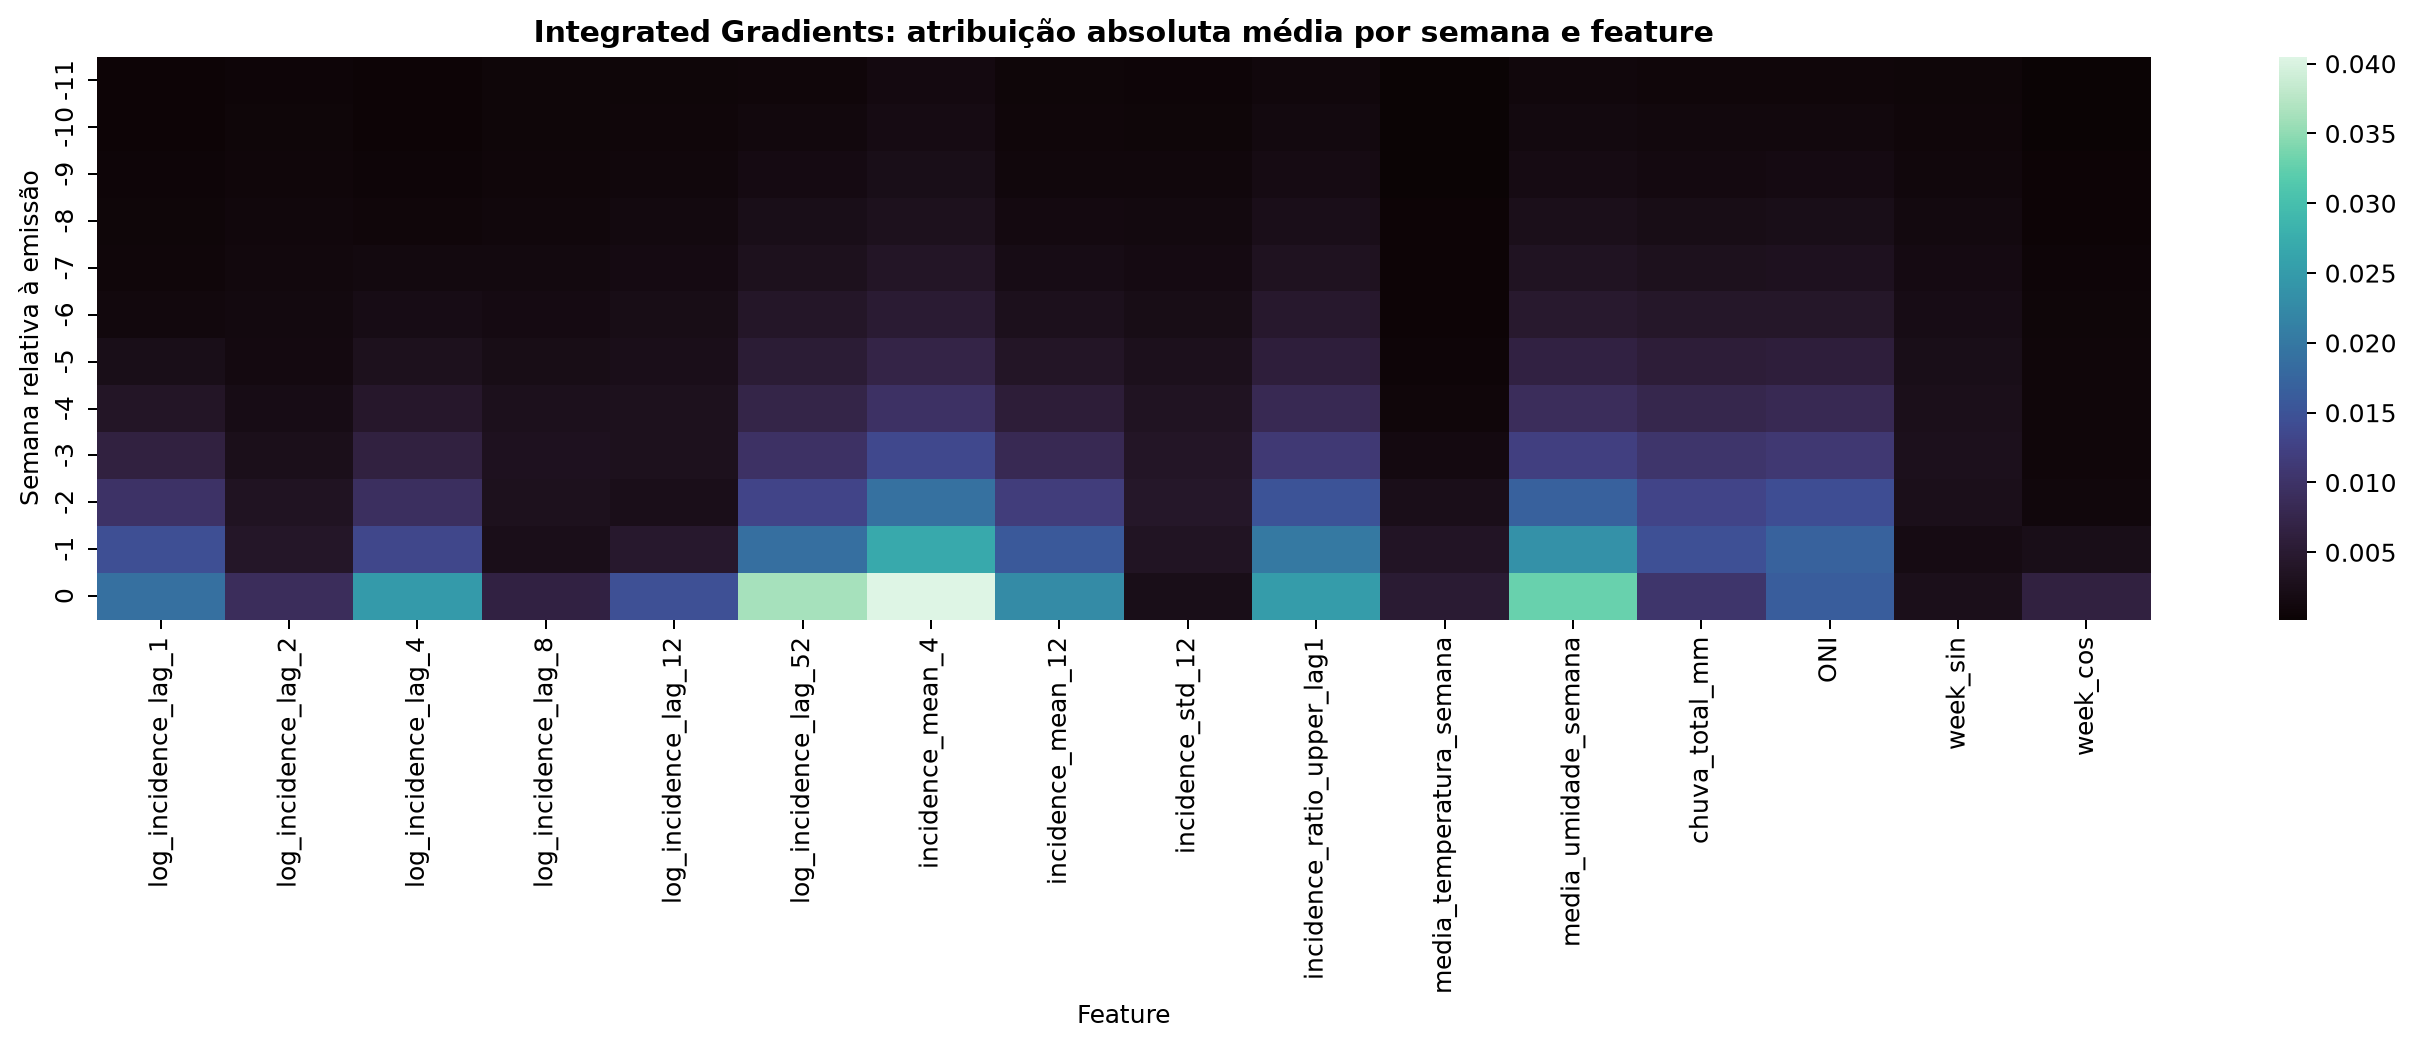

### 8 semanas

,feature,mean_absolute_attribution,mean_signed_attribution
0,incidence_mean_4,0.00571,0.00538
1,media_umidade_semana,0.00497,-0.00144
2,ONI,0.00443,0.00104
3,chuva_total_mm,0.00376,-0.00030
4,log_incidence_lag_52,0.00361,-0.00348
5,incidence_ratio_upper_lag1,0.00340,0.00305
6,log_incidence_lag_8,0.00304,-0.00302
7,incidence_std_12,0.00290,-0.00209
8,incidence_mean_12,0.00251,0.00234
9,log_incidence_lag_4,0.00236,0.00232


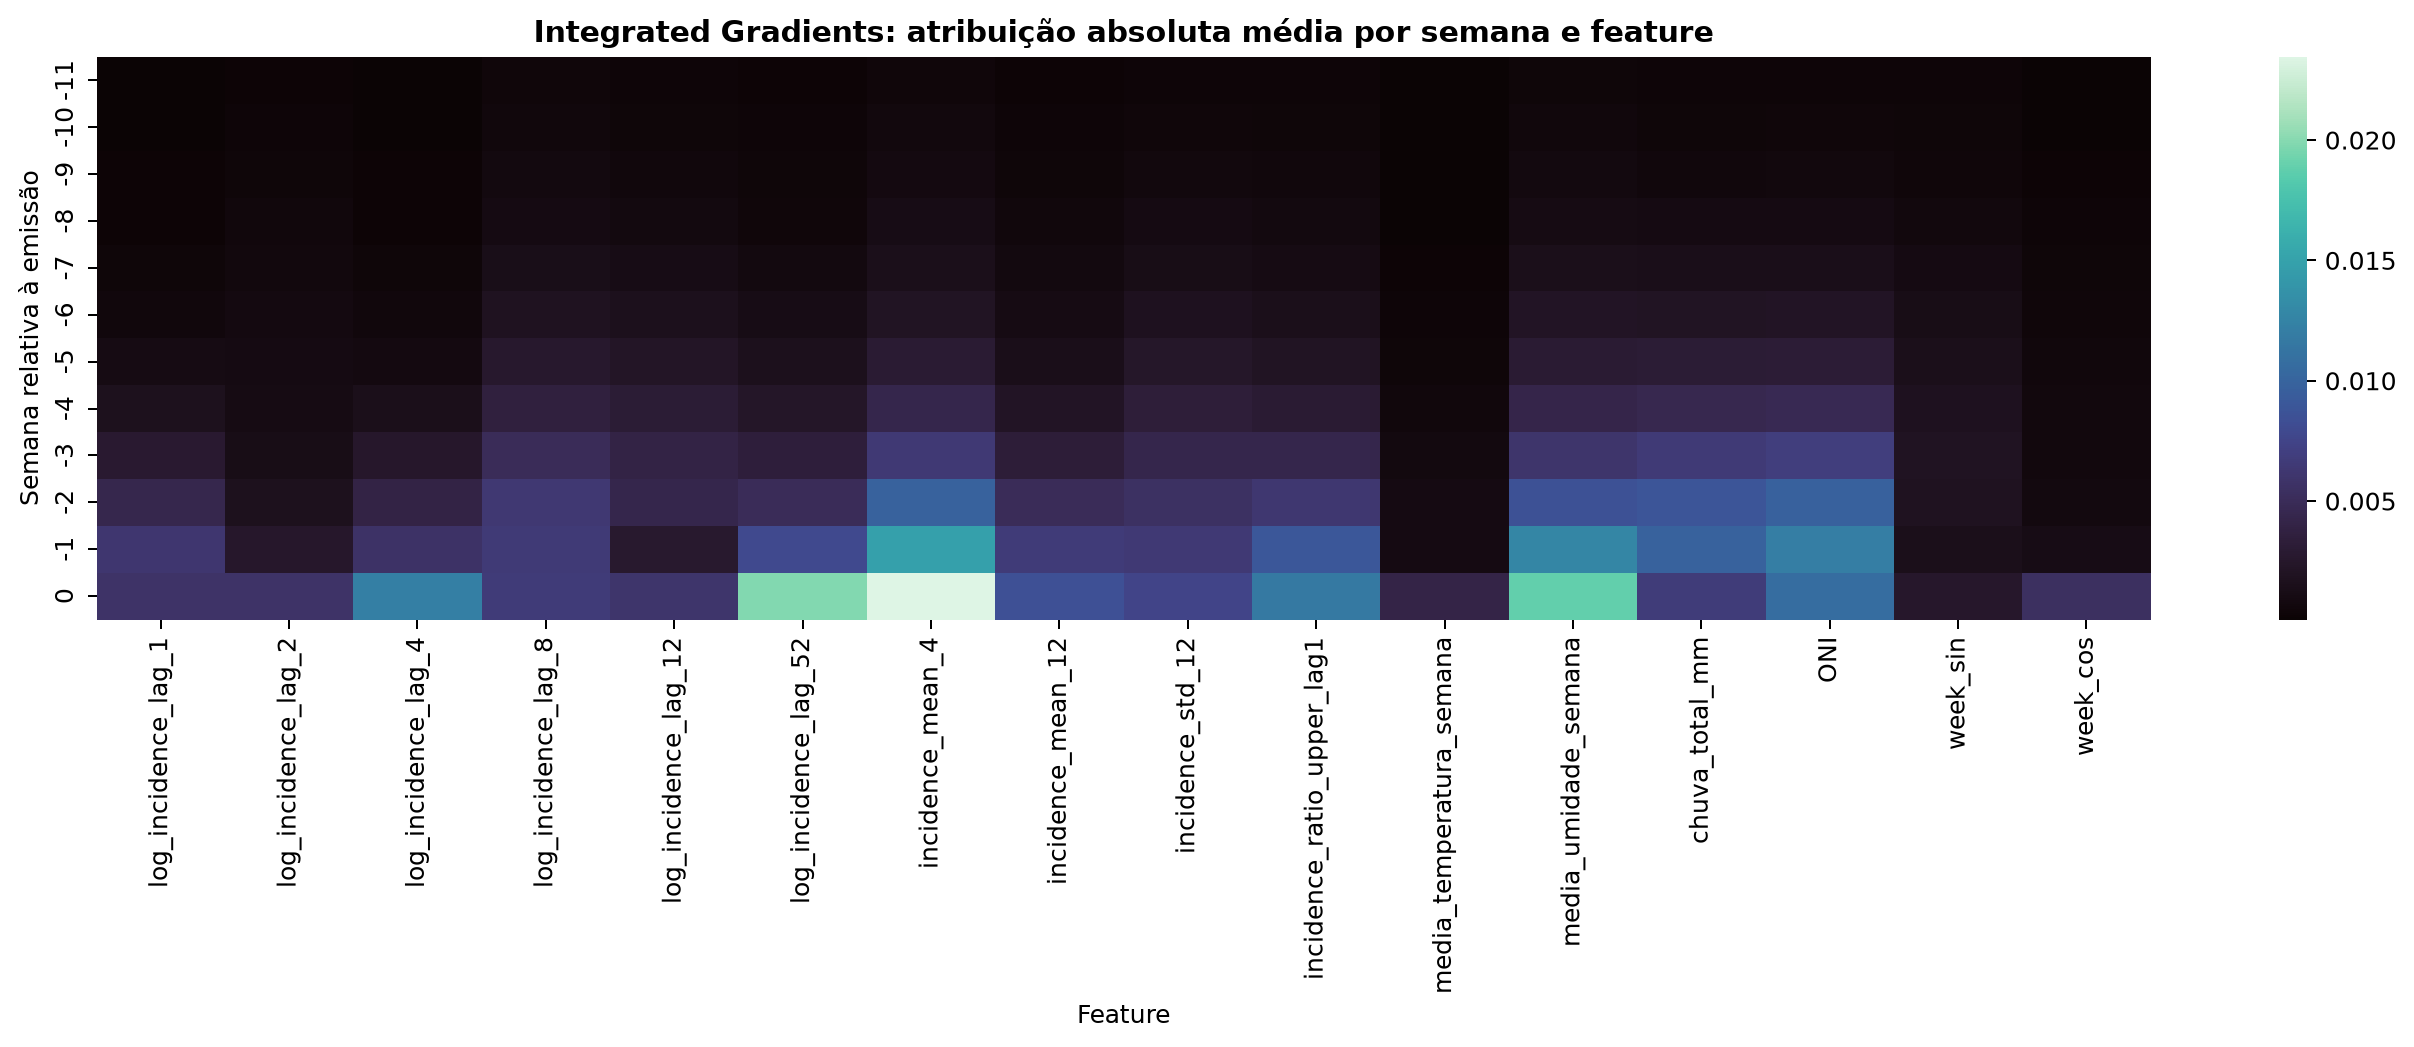

### 12 semanas

,feature,mean_absolute_attribution,mean_signed_attribution
0,log_incidence_lag_8,0.00454,-0.00454
1,incidence_mean_4,0.00363,0.00341
2,media_umidade_semana,0.00355,-0.00060
3,chuva_total_mm,0.00229,0.00012
4,incidence_std_12,0.00219,-0.00151
5,ONI,0.00190,0.00055
6,log_incidence_lag_12,0.00184,-0.00147
7,incidence_mean_12,0.00154,0.00143
8,week_sin,0.00154,0.00062
9,media_temperatura_semana,0.00144,-0.00037


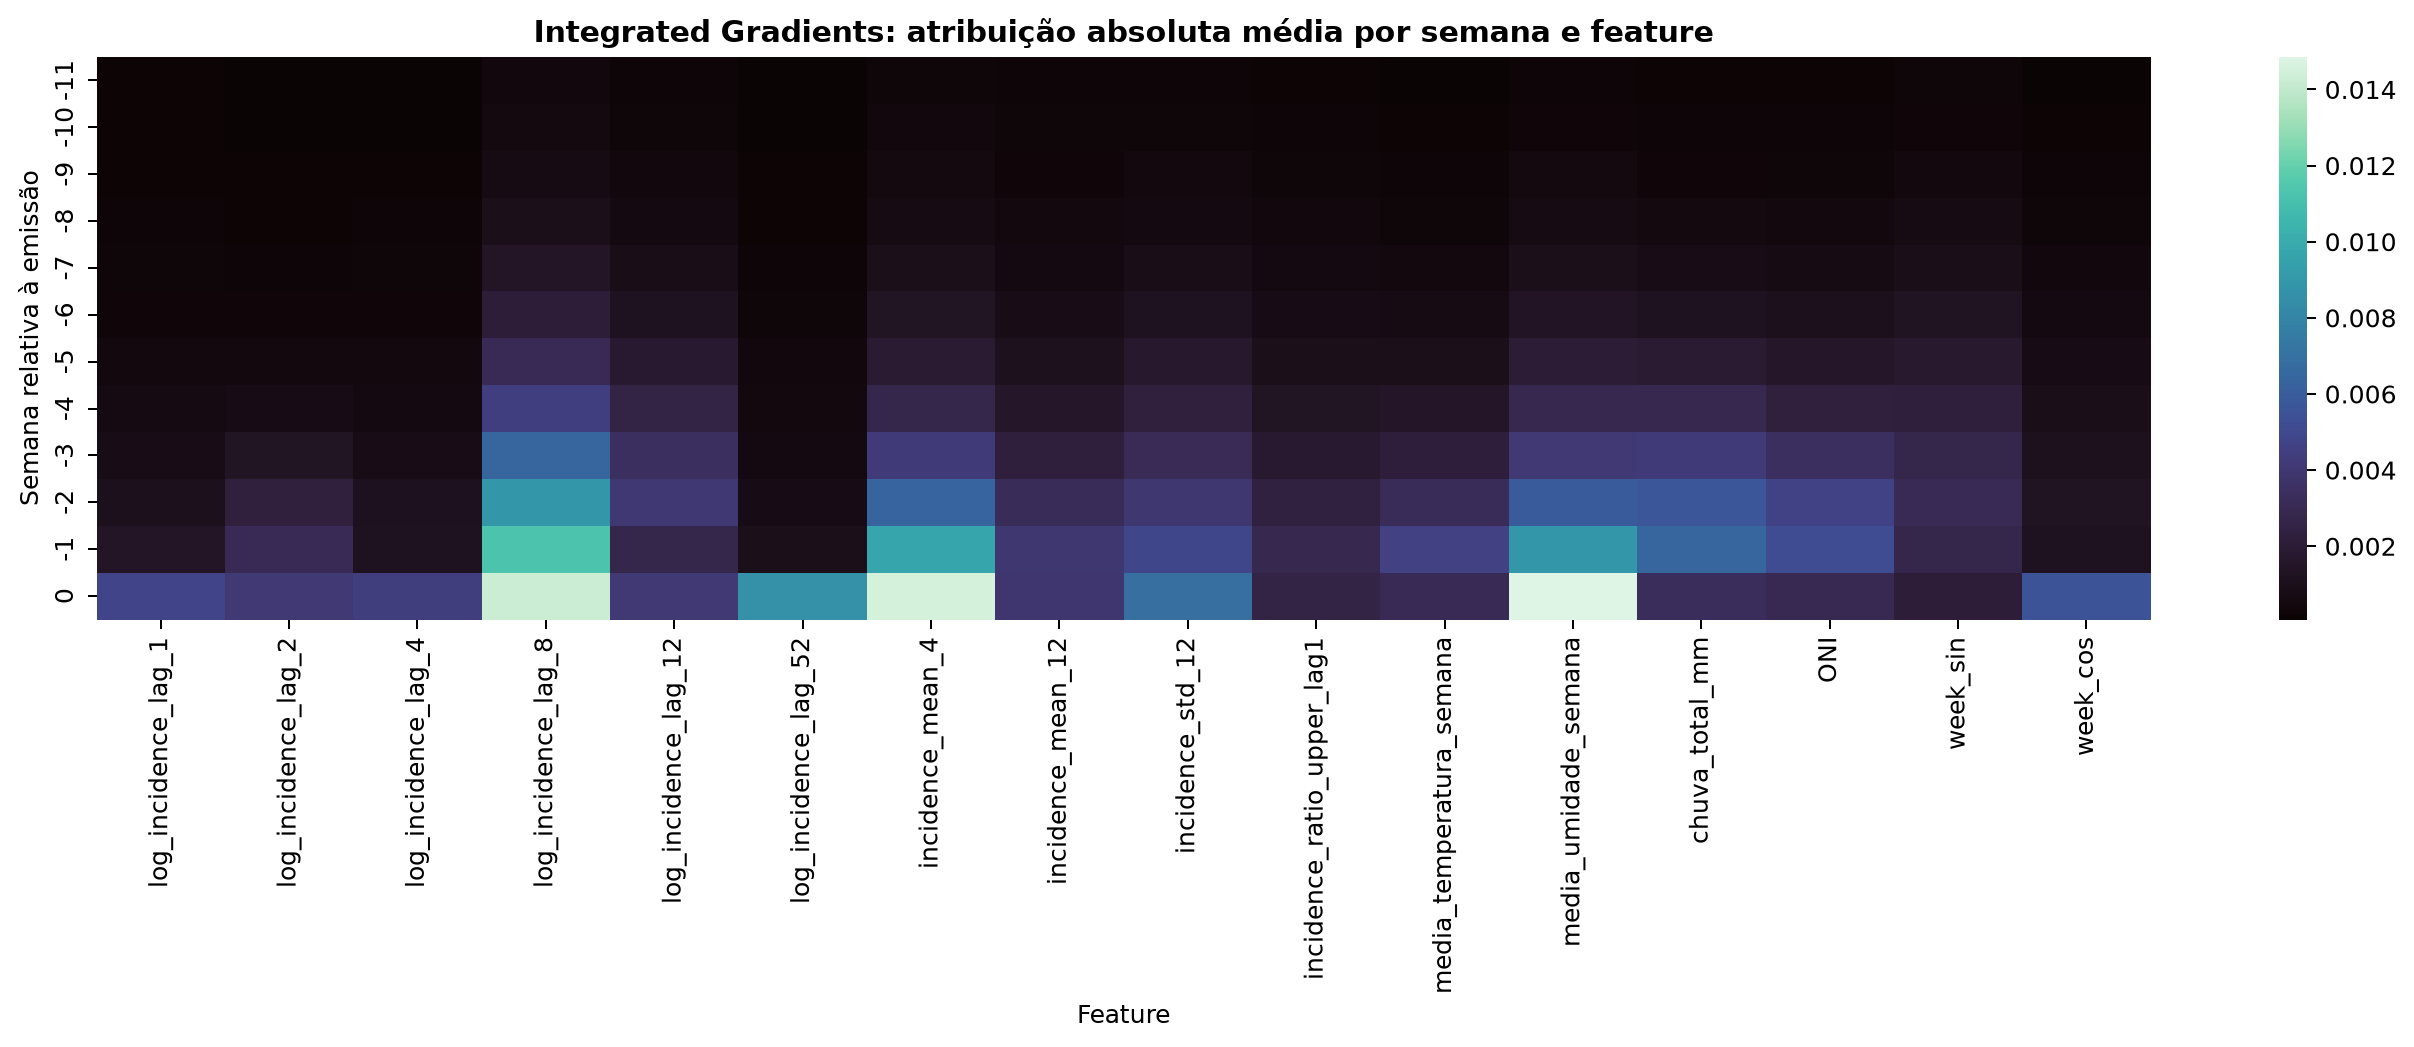

### 16 semanas

,feature,mean_absolute_attribution,mean_signed_attribution
0,log_incidence_lag_8,0.00473,-0.00473
1,incidence_mean_4,0.00279,0.00261
2,media_umidade_semana,0.00247,-0.00030
3,incidence_std_12,0.00240,-0.00162
4,ONI,0.00215,0.00073
5,media_temperatura_semana,0.00186,-0.00050
6,chuva_total_mm,0.00170,0.00014
7,log_incidence_lag_2,0.00166,-0.00153
8,log_incidence_lag_12,0.00132,-0.00052
9,log_incidence_lag_1,0.00121,-0.00109


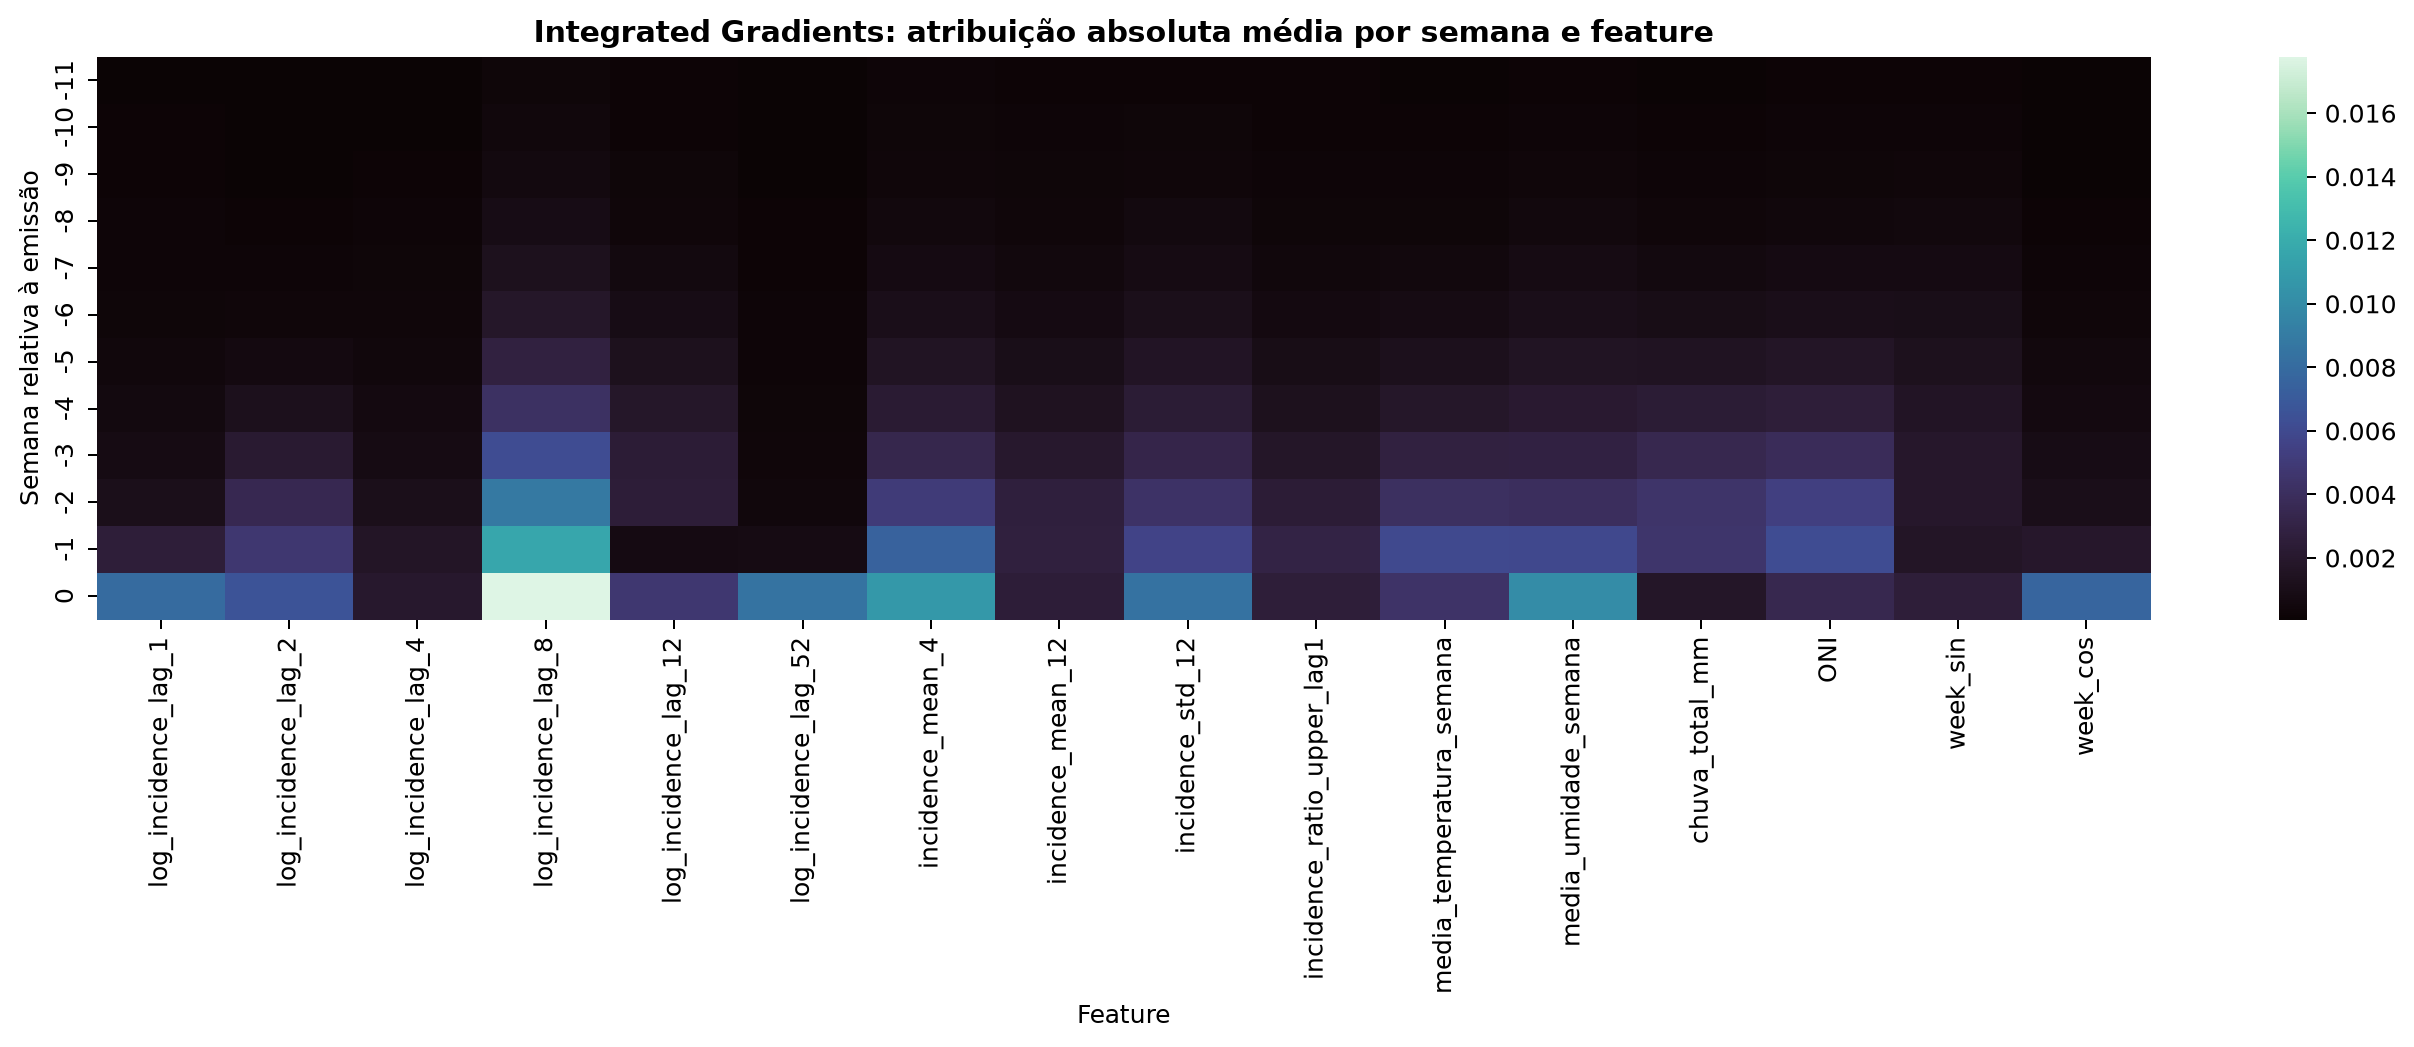

In [9]:
for horizon in (4, 8, 12, 16):
    base = OUTPUT_DIR / f'exact/{horizon:02d}_semanas/captum'
    display(Markdown(f'### {horizon} semanas'))
    display(pd.read_csv(base / 'integrated_gradients_features.csv').head(12).round(5))
    display(Image(filename=str(base / 'integrated_gradients_heatmap.png')))

## 9. Arquivos para o aplicativo

O arquivo legado `app_dados_dengue.json` não é modificado. Cada horizonte recebe:

- `dados/app_previsoes.json`;
- `dados/app_explicabilidade_lstm.json`;
- `metricas/metricas_projeto_mestre.json`;
- figuras auxiliares do Captum.

Todos os JSONs usam datas padronizadas, substituem valores não finitos por `null` e registram versão do modelo, data-alvo, limiar e aviso científico.

In [10]:
for horizon in (4, 8, 12, 16):
    path = PROJECT_ROOT / f'outputs/horizontes/{horizon:02d}_semanas/dados/app_previsoes.json'
    payload = json.loads(path.read_text(encoding='utf-8'))
    display(Markdown(f'### {horizon} semanas'))
    display(pd.Series(payload['previsaoAtual'], name='valor').to_frame())

### 4 semanas

,valor
modelo,random_forest
probabilidade,0.052157
limiar,0.148916
alertaPrevisto,False
nivelRisco,baixo
prAucValidacao,0.64523
prAucTesteRetrospectivo,0.251461
semanaReferencia,2025-12-28
dataAlvo,2026-01-25
regraSelecaoModelo,maior PR AUC na validação


### 8 semanas

,valor
modelo,logistic_regression
probabilidade,0.030188
limiar,0.038914
alertaPrevisto,False
nivelRisco,moderado
prAucValidacao,0.510287
prAucTesteRetrospectivo,0.280791
semanaReferencia,2025-12-28
dataAlvo,2026-02-22
regraSelecaoModelo,maior PR AUC na validação


### 12 semanas

,valor
modelo,lstm_numpy
probabilidade,0.400177
limiar,0.511174
alertaPrevisto,False
nivelRisco,moderado
prAucValidacao,0.363499
prAucTesteRetrospectivo,0.196841
semanaReferencia,2025-12-28
dataAlvo,2026-03-22
regraSelecaoModelo,maior PR AUC na validação


### 16 semanas

,valor
modelo,logistic_regression
probabilidade,0.0
limiar,0.0
alertaPrevisto,False
nivelRisco,baixo
prAucValidacao,0.490178
prAucTesteRetrospectivo,0.218199
semanaReferencia,2025-12-28
dataAlvo,2026-04-19
regraSelecaoModelo,maior PR AUC na validação


## 10. Como interpretar o resultado final

O projeto pode concluir que clima e ENSO ajudam, ajudam apenas em certos horizontes ou não acrescentam desempenho ao histórico de casos. As três respostas são cientificamente válidas.

O aplicativo demonstra que os resultados podem ser produzidos e comunicados automaticamente. Ele não transforma uma associação em causalidade nem torna o sistema pronto para decisões de saúde pública.

## 11. Limitações que devem permanecer na tese

- uma única série municipal;
- poucos episódios independentes;
- ausência atual de validação com alertas oficiais;
- denominador populacional ainda sem fonte formal confirmada;
- disponibilidade real e revisões dos dados precisam ser documentadas;
- 2024–2025 já foi examinado e é avaliação retrospectiva, não teste intocado;
- previsões futuras ou outro município são necessários para validação independente;
- Captum explica o modelo, não mecanismos biológicos.

## 12. Como executar

Execução completa:

```bash
PYTHONPATH=src ./.venv/bin/python scripts/run_master_study.py
```

Verificação técnica rápida:

```bash
PYTHONPATH=src ./.venv/bin/python scripts/run_master_study.py --quick
```

Testes:

```bash
PYTHONPATH=src ./.venv/bin/python -m unittest discover -s tests -v
```